In [2]:
import pandas as pd

PATH = "selogerdata.csv"

pd.set_option('display.max_columns', None)
#pd.set_option('display.max_rows', None)
df = pd.read_csv(PATH)
df.head()



,number,codeinsee,codepostal,cp,etage,idagence,idannonce,idtiers,idtypechauffage,idtypecommerce,idtypecuisine,idtypepublicationsourcecouplage,naturebien,nb_chambres,nb_photos,nb_pieces,position,prix,si_balcon,si_sdEau,si_sdbain,surface,typedebien,ville
0,11,750116,75016,75016,0,178817,144013899,227883,0,0,√©quip√©e,SL,1,2,13,3,11,59000,1,0,0,69.00,Appartement,Paris 16√®me
1,8,750110,75010,75010,0,12089,149750677,3765,0,0,aucune,SL,1,2,7,1,8,77500,0,0,0,8.49,Appartement,Paris 10√®me
2,6,750118,75018,75018,0,115811,138648733,108873,0,0,aucune,SL,1,1,8,2,6,94000,0,0,0,37.00,Appartement,Paris 18√®me
3,16,750110,75010,75010,0,12089,149750679,3765,0,0,aucune,SL,1,2,4,1,16,96000,0,0,0,10.26,Appartement,Paris 10√®me
4,4,750116,75016,75016,0,97567,147153067,145098,0,0,0,SL,1,1,5,2,4,100000,0,0,0,14.93,Appartement,Paris 16√®me


## Prétraitement des données

In [3]:
df['idtypecuisine'].unique()

array(['√©quip√©e', 'aucune', '0', 'coin cuisine √©quip√©',
       'coin cuisine', 's√©par√©e', 's√©par√©e √©quip√©e', 'am√©ricaine',
       'am√©ricaine √©quip√©e', '-1'], dtype=object)

In [4]:
df['idtypecuisine'] = df['idtypecuisine'].replace({
    '√©quip√©e': 'équipée',
    'coin cuisine √©quip√©': 'coin cuisine équipée',
    's√©par√©e': 'séparée',
    's√©par√©e √©quip√©e': 'séparée équipée',
    'am√©ricaine': 'américaine',
    'am√©ricaine √©quip√©e': 'américaine équipée',
    '0':'categorie_0',
    '-1': 'categorie_-1'
})

df['idtypecuisine'].unique()

array(['équipée', 'aucune', 'categorie_0', 'coin cuisine équipée',
       'coin cuisine', 'séparée', 'séparée équipée', 'américaine',
       'américaine équipée', 'categorie_-1'], dtype=object)

In [5]:
# Afficher les modalités uniques de la variable Ville
df['ville'].unique()

array(['Paris 16√®me', 'Paris 10√®me', 'Paris 18√®me', 'Melun',
       'Corbeil Essonnes', '√âtampes', 'Issou', 'Limay', '√âvry', 'Avon',
       'Evry', 'Saint-Denis', 'Trappes', 'Ris Orangis', 'Paris 19√®me',
       'Paris 14√®me', '√âpinay-sous-S√©nart', 'Eragny sur Oise',
       'Argenteuil', 'Bessancourt', 'Etampes', 'Montlhery', 'Gagny',
       'Fleury Merogis', 'Villeparisis', 'Fosses', 'Vaujours', 'Les Ulis',
       'Meaux', 'Pontoise', 'Cergy', 'Verneuil sur Seine',
       'Brie Comte Robert', 'Carrieres sous Poissy', 'H√©ricy', 'Igny',
       'Paris 20√®me', 'Les Pavillons-sous-Bois', 'Mennecy',
       'Vert le Petit', 'Morsang-sur-Orge', 'Linas', 'Mandres les Roses',
       'Paris 17√®me', 'Villepinte', 'Paris 2√®me', 'Paris 15√®me',
       'Paris 6√®me', 'Paris 3√®me', 'Paris 8√®me', 'Paris 5√®me',
       'Paris 11√®me', 'Paris 9√®me', 'Paris 13√®me', 'Paris 12√®me',
       'Garches', 'Chatou', 'Sucy en Brie', 'Louveciennes', 'Le Pecq',
       'Enghien les Bains', 'Saint Ger

In [6]:
df['ville'] = (
    df['ville']
    .str.replace('√©', 'é')
    .str.replace('√®', 'è')
    .str.replace('√â', 'É')
)

df['ville'].unique()

array(['Paris 16ème', 'Paris 10ème', 'Paris 18ème', 'Melun',
       'Corbeil Essonnes', 'Étampes', 'Issou', 'Limay', 'Évry', 'Avon',
       'Evry', 'Saint-Denis', 'Trappes', 'Ris Orangis', 'Paris 19ème',
       'Paris 14ème', 'Épinay-sous-Sénart', 'Eragny sur Oise',
       'Argenteuil', 'Bessancourt', 'Etampes', 'Montlhery', 'Gagny',
       'Fleury Merogis', 'Villeparisis', 'Fosses', 'Vaujours', 'Les Ulis',
       'Meaux', 'Pontoise', 'Cergy', 'Verneuil sur Seine',
       'Brie Comte Robert', 'Carrieres sous Poissy', 'Héricy', 'Igny',
       'Paris 20ème', 'Les Pavillons-sous-Bois', 'Mennecy',
       'Vert le Petit', 'Morsang-sur-Orge', 'Linas', 'Mandres les Roses',
       'Paris 17ème', 'Villepinte', 'Paris 2ème', 'Paris 15ème',
       'Paris 6ème', 'Paris 3ème', 'Paris 8ème', 'Paris 5ème',
       'Paris 11ème', 'Paris 9ème', 'Paris 13ème', 'Paris 12ème',
       'Garches', 'Chatou', 'Sucy en Brie', 'Louveciennes', 'Le Pecq',
       'Enghien les Bains', 'Saint Germain en Laye', 'Paris 

In [7]:
df['nb_pieces'] = df['nb_pieces'].astype('Int64')
df.head()


,number,codeinsee,codepostal,cp,etage,idagence,idannonce,idtiers,idtypechauffage,idtypecommerce,idtypecuisine,idtypepublicationsourcecouplage,naturebien,nb_chambres,nb_photos,nb_pieces,position,prix,si_balcon,si_sdEau,si_sdbain,surface,typedebien,ville
0,11,750116,75016,75016,0,178817,144013899,227883,0,0,équipée,SL,1,2,13,3,11,59000,1,0,0,69.00,Appartement,Paris 16ème
1,8,750110,75010,75010,0,12089,149750677,3765,0,0,aucune,SL,1,2,7,1,8,77500,0,0,0,8.49,Appartement,Paris 10ème
2,6,750118,75018,75018,0,115811,138648733,108873,0,0,aucune,SL,1,1,8,2,6,94000,0,0,0,37.00,Appartement,Paris 18ème
3,16,750110,75010,75010,0,12089,149750679,3765,0,0,aucune,SL,1,2,4,1,16,96000,0,0,0,10.26,Appartement,Paris 10ème
4,4,750116,75016,75016,0,97567,147153067,145098,0,0,categorie_0,SL,1,1,5,2,4,100000,0,0,0,14.93,Appartement,Paris 16ème


In [8]:
df.describe()

,number,codeinsee,codepostal,cp,etage,idagence,idannonce,idtiers,idtypechauffage,idtypecommerce,naturebien,nb_chambres,nb_photos,nb_pieces,position,prix,si_balcon,si_sdEau,si_sdbain,surface
count,8899.000000,8899.000000,8899.000000,8899.000000,8899.0,8899.000000,8.899000e+03,8899.000000,8899.0,8899.0,8899.000000,8899.000000,8899.000000,8899.0,8899.000000,8.899000e+03,8899.000000,8899.0,8899.0,8899.000000
mean,9.531296,751745.680189,75186.144735,75186.144735,0.0,124110.094280,1.473531e+08,136989.252500,0.0,0.0,1.638723,2.319474,9.697269,3.838746,9.531296,1.210579e+06,0.271716,0.0,0.0,96.070707
std,5.765614,16287.896954,1660.091189,1660.091189,0.0,104338.907661,3.661055e+06,109732.960794,0.0,0.0,0.931184,1.170877,4.511174,1.483164,5.765614,4.462923e+05,0.444869,0.0,0.0,38.127731
min,0.000000,750101.000000,75001.000000,75001.000000,0.0,33.000000,7.437284e+07,98.000000,0.0,0.0,1.000000,1.000000,0.000000,1.0,0.000000,5.900000e+04,0.000000,0.0,0.0,0.000000
25%,5.000000,750108.000000,75008.000000,75008.000000,0.0,39738.000000,1.463174e+08,26516.000000,0.0,0.0,1.000000,1.000000,6.000000,3.0,5.000000,7.950000e+05,0.000000,0.0,0.0,66.400000
50%,10.000000,750114.000000,75014.000000,75014.000000,0.0,93920.000000,1.486361e+08,123925.000000,0.0,0.0,1.000000,2.000000,9.000000,4.0,10.000000,1.475000e+06,0.000000,0.0,0.0,93.000000
75%,15.000000,750116.000000,75017.000000,75017.000000,0.0,203657.000000,1.495161e+08,213489.000000,0.0,0.0,3.000000,3.000000,12.000000,5.0,15.000000,1.490000e+06,1.000000,0.0,0.0,129.000000
max,19.000000,950500.000000,95880.000000,95880.000000,0.0,362103.000000,1.502498e+08,425123.000000,0.0,0.0,3.000000,22.000000,27.000000,53.0,19.000000,2.000000e+06,1.000000,0.0,0.0,250.000000


In [9]:
# Supprimer les colonnes etage, idtypechauffage, idtypecommerce, si_sdEau, si_sdbain

df = df.drop(columns=['etage', 'idtypechauffage', 'idtypecommerce', 'si_sdEau', 'si_sdbain'])
df.head()

,number,codeinsee,codepostal,cp,idagence,idannonce,idtiers,idtypecuisine,idtypepublicationsourcecouplage,naturebien,nb_chambres,nb_photos,nb_pieces,position,prix,si_balcon,surface,typedebien,ville
0,11,750116,75016,75016,178817,144013899,227883,équipée,SL,1,2,13,3,11,59000,1,69.00,Appartement,Paris 16ème
1,8,750110,75010,75010,12089,149750677,3765,aucune,SL,1,2,7,1,8,77500,0,8.49,Appartement,Paris 10ème
2,6,750118,75018,75018,115811,138648733,108873,aucune,SL,1,1,8,2,6,94000,0,37.00,Appartement,Paris 18ème
3,16,750110,75010,75010,12089,149750679,3765,aucune,SL,1,2,4,1,16,96000,0,10.26,Appartement,Paris 10ème
4,4,750116,75016,75016,97567,147153067,145098,categorie_0,SL,1,1,5,2,4,100000,0,14.93,Appartement,Paris 16ème


In [10]:
(df['codepostal'] == df['cp']).all()

True

In [11]:
# Supprimer la colonne cp car elle est redondante avec codepostal

df = df.drop(columns=['cp'])
df.head()

,number,codeinsee,codepostal,idagence,idannonce,idtiers,idtypecuisine,idtypepublicationsourcecouplage,naturebien,nb_chambres,nb_photos,nb_pieces,position,prix,si_balcon,surface,typedebien,ville
0,11,750116,75016,178817,144013899,227883,équipée,SL,1,2,13,3,11,59000,1,69.00,Appartement,Paris 16ème
1,8,750110,75010,12089,149750677,3765,aucune,SL,1,2,7,1,8,77500,0,8.49,Appartement,Paris 10ème
2,6,750118,75018,115811,138648733,108873,aucune,SL,1,1,8,2,6,94000,0,37.00,Appartement,Paris 18ème
3,16,750110,75010,12089,149750679,3765,aucune,SL,1,2,4,1,16,96000,0,10.26,Appartement,Paris 10ème
4,4,750116,75016,97567,147153067,145098,categorie_0,SL,1,1,5,2,4,100000,0,14.93,Appartement,Paris 16ème


In [12]:
(df['number'] == df['position']).all()

True

In [13]:
# Supprimer la colonne position car elle est redondante avec number

df = df.drop(columns=['position'])
df.head()

,number,codeinsee,codepostal,idagence,idannonce,idtiers,idtypecuisine,idtypepublicationsourcecouplage,naturebien,nb_chambres,nb_photos,nb_pieces,prix,si_balcon,surface,typedebien,ville
0,11,750116,75016,178817,144013899,227883,équipée,SL,1,2,13,3,59000,1,69.00,Appartement,Paris 16ème
1,8,750110,75010,12089,149750677,3765,aucune,SL,1,2,7,1,77500,0,8.49,Appartement,Paris 10ème
2,6,750118,75018,115811,138648733,108873,aucune,SL,1,1,8,2,94000,0,37.00,Appartement,Paris 18ème
3,16,750110,75010,12089,149750679,3765,aucune,SL,1,2,4,1,96000,0,10.26,Appartement,Paris 10ème
4,4,750116,75016,97567,147153067,145098,categorie_0,SL,1,1,5,2,100000,0,14.93,Appartement,Paris 16ème


In [14]:
df.rename(columns={'idtypepublicationsourcecouplage': 'idtypepublication'}, inplace=True)
df.head()

,number,codeinsee,codepostal,idagence,idannonce,idtiers,idtypecuisine,idtypepublication,naturebien,nb_chambres,nb_photos,nb_pieces,prix,si_balcon,surface,typedebien,ville
0,11,750116,75016,178817,144013899,227883,équipée,SL,1,2,13,3,59000,1,69.00,Appartement,Paris 16ème
1,8,750110,75010,12089,149750677,3765,aucune,SL,1,2,7,1,77500,0,8.49,Appartement,Paris 10ème
2,6,750118,75018,115811,138648733,108873,aucune,SL,1,1,8,2,94000,0,37.00,Appartement,Paris 18ème
3,16,750110,75010,12089,149750679,3765,aucune,SL,1,2,4,1,96000,0,10.26,Appartement,Paris 10ème
4,4,750116,75016,97567,147153067,145098,categorie_0,SL,1,1,5,2,100000,0,14.93,Appartement,Paris 16ème


In [15]:
df.duplicated().sum()

5063

In [16]:
df.shape

(8899, 17)

In [17]:
df.drop_duplicates(inplace=True)
df.shape

(3836, 17)

## Analyses statistiques

In [18]:
# Calculer la moyenne des prix en fonction des modalités de la variable si_balcon et arrondir à deux chiffres après la virgule
df.groupby('si_balcon')['prix'].mean().round(2)

si_balcon
0    774409.34
1    860789.54
Name: prix, dtype: float64

In [19]:
# Calculer le prix au mètre carré et ajouter la colonne

df['prix_m2'] = (df['prix'] / df['surface']).round(2)
df.head()



,number,codeinsee,codepostal,idagence,idannonce,idtiers,idtypecuisine,idtypepublication,naturebien,nb_chambres,nb_photos,nb_pieces,prix,si_balcon,surface,typedebien,ville,prix_m2
0,11,750116,75016,178817,144013899,227883,équipée,SL,1,2,13,3,59000,1,69.00,Appartement,Paris 16ème,855.07
1,8,750110,75010,12089,149750677,3765,aucune,SL,1,2,7,1,77500,0,8.49,Appartement,Paris 10ème,9128.39
2,6,750118,75018,115811,138648733,108873,aucune,SL,1,1,8,2,94000,0,37.00,Appartement,Paris 18ème,2540.54
3,16,750110,75010,12089,149750679,3765,aucune,SL,1,2,4,1,96000,0,10.26,Appartement,Paris 10ème,9356.73
4,4,750116,75016,97567,147153067,145098,categorie_0,SL,1,1,5,2,100000,0,14.93,Appartement,Paris 16ème,6697.92


In [20]:
# Afficher la ligne où la surface est nulle

df[df['surface'] == 0]

,number,codeinsee,codepostal,idagence,idannonce,idtiers,idtypecuisine,idtypepublication,naturebien,nb_chambres,nb_photos,nb_pieces,prix,si_balcon,surface,typedebien,ville,prix_m2
2030,3,750116,75016,76979,147347131,108380,categorie_0,SL,1,1,6,4,747840,0,0.0,Appartement,Paris 16ème,inf


In [21]:
# Supprimer la ligne où la surface est nulle

df.drop(index=2030, inplace=True)

In [28]:
df['prix_m2'] = (df['prix'] / df['surface']).round(2)
df.head()


,number,codeinsee,codepostal,idagence,idannonce,idtiers,idtypecuisine,idtypepublication,naturebien,nb_chambres,nb_photos,nb_pieces,prix,si_balcon,surface,typedebien,ville,prix_m2
0,11,750116,75016,178817,144013899,227883,équipée,SL,1,2,13,3,59000,1,69.00,Appartement,Paris 16ème,855.07
1,8,750110,75010,12089,149750677,3765,aucune,SL,1,2,7,1,77500,0,8.49,Appartement,Paris 10ème,9128.39
2,6,750118,75018,115811,138648733,108873,aucune,SL,1,1,8,2,94000,0,37.00,Appartement,Paris 18ème,2540.54
3,16,750110,75010,12089,149750679,3765,aucune,SL,1,2,4,1,96000,0,10.26,Appartement,Paris 10ème,9356.73
4,4,750116,75016,97567,147153067,145098,categorie_0,SL,1,1,5,2,100000,0,14.93,Appartement,Paris 16ème,6697.92


In [ ]:
# Calculer le pridx moyen en fonction du si_balcon et de typedebien

df.groupby(["si_balcon", "typedebien"])["prix"].mean().unstack()

typedebien,Appartement,Loft/Atelier/Surface
si_balcon,,
0,771021.396474,1.002965e+06
1,860608.034598,9.150000e+05


In [33]:
df['typedebien'].value_counts()

Appartement             3789
Loft/Atelier/Surface      46
Name: typedebien, dtype: int64

## Visualisation des données

<Axes: xlabel='prix_m2', ylabel='Count'>

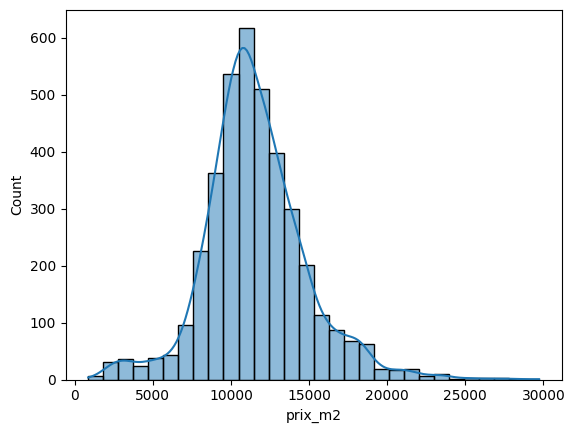

In [37]:
# Visualiser la variable prix au mètre carré

import seaborn as sns

sns.histplot(df['prix_m2'], bins=30, kde=True)


In [22]:
# Lire les fichier les trois fichiers dans le dossier seloger
import os

dossier = "Seloger"

dfs = {}
for fichier in os.listdir(dossier):
    if fichier.endswith(".csv"):
        dfs[fichier] = pd.read_csv(os.path.join(dossier, fichier), encoding="utf-8")
        print(fichier, dfs[fichier].shape)

df_annonces = dfs["seloger_annonces.csv"]
df_localisation = dfs["seloger_localisation.csv"]
df_logements = dfs["seloger_logements.csv"]

seloger_localisation.csv (8899, 6)
seloger_logements.csv (8899, 13)
seloger_annonces.csv (8899, 8)


In [ ]:
# Fusionner les trois fichiers sur id_ligne
df = df_annonces.merge(df_logements, on="id_ligne").merge(df_localisation, on="id_ligne")

print(df.shape)
df.head()

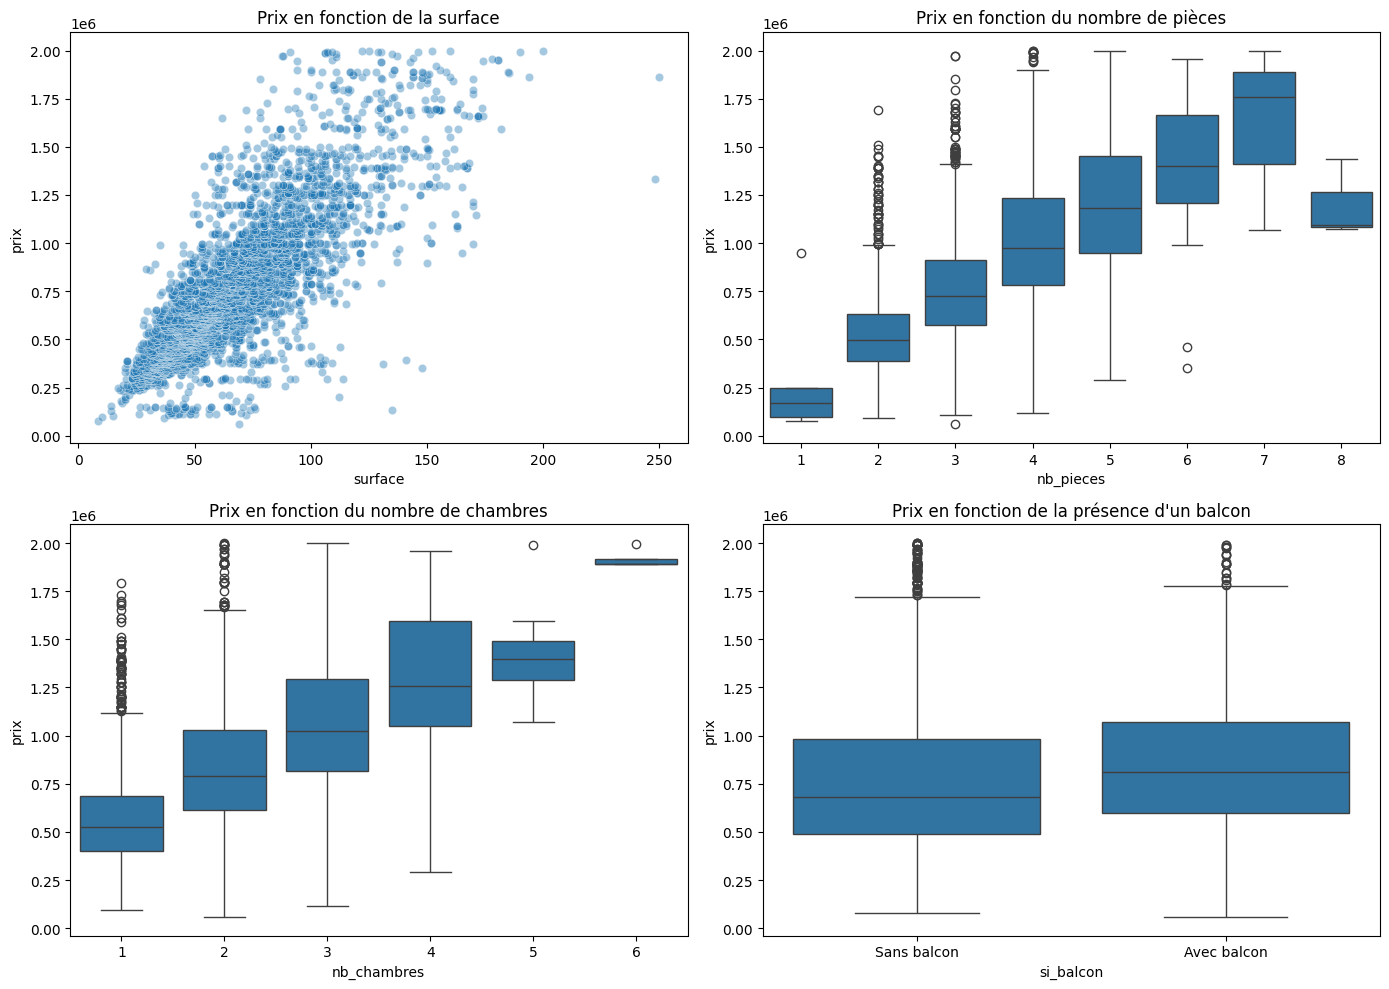

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

# On écarte les valeurs aberrantes (surface nulle, 53 pièces, 22 chambres)
d = df[(df["surface"] > 0) & (df["nb_pieces"] <= 8) & (df["nb_chambres"] <= 6)]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.scatterplot(data=d, x="surface", y="prix", alpha=0.4, ax=axes[0, 0])
axes[0, 0].set_title("Prix en fonction de la surface")

sns.boxplot(data=d, x="nb_pieces", y="prix", ax=axes[0, 1])
axes[0, 1].set_title("Prix en fonction du nombre de pièces")

sns.boxplot(data=d, x="nb_chambres", y="prix", ax=axes[1, 0])
axes[1, 0].set_title("Prix en fonction du nombre de chambres")

sns.boxplot(data=d, x="si_balcon", y="prix", ax=axes[1, 1])
axes[1, 1].set_xticks([0, 1], ["Sans balcon", "Avec balcon"])
axes[1, 1].set_title("Prix en fonction de la présence d'un balcon")

plt.tight_layout()
plt.show()